# **Name: Atharv Kulkarni**
## **PRN: 245109074**
---
# Session 0 — Getting Started with Google Colab
### Robotics Lab — Robotic Arm Simulation with PyBullet
Before Session 1, complete this short walkthrough once. It takes about 5 minutes and covers
everything you need: creating access, writing your first line of code, and running it.


## Step 1 — Get a Google account (skip if you already have one)

Colab runs on your Google account — the same one used for Gmail, Google Drive, or Classroom.
No separate signup or software install is needed for Colab itself.

- If you already have a Google/Gmail account, skip to Step 2.
- If not, go to **accounts.google.com** and click **Create account**. It's free and takes about
  2 minutes. You do not need to use it for email — you can create it purely to access Google's
  free tools like Colab and Drive.


## Step 2 — Open Google Colab

1. Go to **colab.research.google.com** in any modern browser (Chrome or Firefox recommended).
2. If asked, sign in with your Google account.
3. You'll see a "Welcome to Colab" screen with a file picker. Close it or click **New notebook**
   at the bottom — this creates a blank, empty notebook you can experiment in.


## Step 3 — Write and run your first code

A fresh notebook opens with one empty **code cell** (a grey box). This is where you type Python
code.

1. Click inside the empty cell.
2. Type exactly this: `print("Hello, robot!")`
3. Run the cell by pressing **Shift + Enter** on your keyboard, or by clicking the **▶ play
   button** that appears on the left edge of the cell when you hover over it.
4. The first time you run any cell, Colab takes a few seconds to connect to a free virtual
   machine in the background (you'll see "Connecting..." briefly, top-right). After that,
   cells run almost instantly.
5. Your output — `Hello, robot!` — appears directly below the cell.

That's the entire loop you'll use for the rest of this lab: **write code in a cell → run it with
Shift+Enter → read the output below it.**


## Step 4 — Try running a real simulation cell

The cell below is a taste of what you'll do in Session 1: it installs PyBullet, loads a simulated
robot arm, and takes a snapshot so you can *see* it. Run it now with Shift+Enter and watch what
happens — don't worry about understanding the code yet, that's what Session 1 is for.


pybullet build time: Oct 15 2026 18:47:44


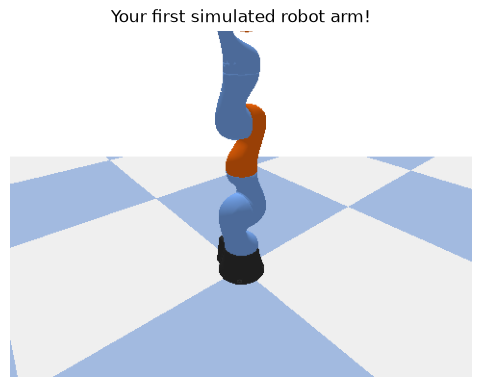

In [1]:
!pip install pybullet -q
import pybullet as p
import pybullet_data
import numpy as np
import matplotlib.pyplot as plt

client = p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.setGravity(0, 0, -9.8)
p.loadURDF("plane.urdf")
robot_id = p.loadURDF("kuka_iiwa/model.urdf", basePosition=[0, 0, 0], useFixedBase=True)
for _ in range(20):
    p.stepSimulation()

view_matrix = p.computeViewMatrixFromYawPitchRoll((0, 0, 0.4), 1.4, 50, -30, 0, 2)
proj_matrix = p.computeProjectionMatrixFOV(fov=60, aspect=480/360, nearVal=0.1, farVal=3.0)
img = p.getCameraImage(480, 360, view_matrix, proj_matrix, renderer=p.ER_TINY_RENDERER)
rgb = np.reshape(img[2], (360, 480, 4))[:, :, :3]
plt.figure(figsize=(6, 4.5))
plt.imshow(rgb)
plt.axis('off')
plt.title("Your first simulated robot arm!")
plt.show()


## Step 5 — Save your own copy

Before moving to Session 1:

1. Go to `File > Save a copy in Drive`.
2. This creates your own personal, editable copy in your Google Drive — nothing you do affects
   anyone else's copy.
3. Rename it if you like (e.g., "Session 0 - [Your Name]").

## Step 6 — Open Session 1

Open **Session1_Orientation.ipynb** the same way: upload it at colab.research.google.com
(`File > Upload notebook`), or open it directly if your instructor shared it via a Drive folder
or GitHub link. Then immediately do `File > Save a copy in Drive` before running anything.

You're ready to start the lab.


## Summary & Key Learnings
- In this introductory session, I set up and validated my Python simulation environment for robotic arm kinematics using PyBullet.
- I learned how to instantiate a headless physics client (`p.DIRECT`), load URDF environment assets (`plane.urdf` and `kuka_iiwa/model.urdf`), and step the physical simulation.
- I rendered the simulated robotic manipulator from synthetic camera projection matrices and visualized the inline output using Matplotlib.
- I established a reproducible workflow for writing and running modular simulation cells without repetitive external package downloads.